# Background

- **Author**: 許以琳
- **Created At**: 2026-11-10
- **Research Motivation and Context (why are we interested in the findings?)：** 本組第一階段要依候選人背景分群。先前的 k-means（[candidate_kmeans_elbow.ipynb](candidate_kmeans_elbow.ipynb)，保留不改）需把類別變數拆成 0/1 欄位，導致政黨與學歷權重偏高、分群幾乎等於「政黨＋學歷」。本 notebook 改用 proposal 原規劃的 **Gower 距離＋PAM（k-medoids）**：Gower 距離可直接處理類別與數值混合的資料，且六個變數權重相同。輸入資料與 k-means 相同：`data/processed/candidates_scope_g1_g6_20261108.csv`（267 位候選人，產生方式見 [處理筆記本](../data/code/merge_scope_g1_g6_20261108.ipynb)），分群變數 G1 年齡、G2 性別、G3 學歷、G4 政黨、G5 首次參選、G6 政治家族。本 notebook 對 k = 1–10 都跑 PAM，提供選 k 的依據；k 由許以琳決定後再做最終分群。
- **Main Findings and Takeaways：** (1) 選 k：總成本的平移首尾連線切點為 k = 4，但 k = 3–5 差異很小；輪廓係數 0.21–0.29 偏低，群結構不明顯。許以琳選定 k = 4。(2) PAM k = 4 的四群（76／74／66／51）依性別、政黨、首次參選切開：第 1 群全為女性（國民黨 50%、民進黨 25%、政治家族 34% 最高）；第 2 群以民進黨男性為主（民進黨 77%、平均 46.6 歲最年輕）；第 3 群全為男性、國民黨 70%、平均 58.1 歲最年長；第 4 群為無黨籍素人（無黨籍 82%、首次參選 73%、大學學歷 59%、縣市長 39%）。和 k-means（幾乎等於政黨＋學歷）不同，性別與首次參選也成為分群的軸。(3) 穩健性：抽 80% 重跑 50 次，PAM 與全樣本結果的平均 ARI 只有 0.458（k-means 0.886）；排除報導／約略年齡的 22 人後 ARI 0.382（k-means 0.914）。PAM 與 k-means 兩種分群的 ARI 為 0.192，差異很大。PAM 的群邊界對樣本變動很敏感，個別候選人的群別不宜直接使用。
- **Future Direction：** 兩種方法都顯示群結構偏弱；k-means 穩定但幾乎等於政黨＋學歷，PAM 類型較有意義但不穩定。後續策略比較可考慮以 k-means 為主、PAM 為輔，或改用 proposal 的備案（事先定義的規則型類型）。
<!-- Deliver the ipynb in finding/ directly for review, retaining actual outputs.
HTML is not required and is produced only when separately requested. Use the
student's requested or existing filename, or a descriptive basename. Created At
is the fixed creation date. Follow the project-root FINDING-RULES.md for handoff
and external-action scope. -->


In [1]:
# Load packages here
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
# 本機 Windows 的應用程式控制原則封鎖 scikit-learn 的編譯元件，PAM 與輪廓係數以 numpy 實作。


In [2]:
# Load input data here and please finish all the data manipulation here.
def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "AGENTS.md").is_file() and (candidate / "templates").is_dir():
            return candidate
    raise FileNotFoundError("請在含 AGENTS.md 與 templates/ 的專案內開啟本 notebook。")

PROJECT_ROOT = find_project_root()
DATA_REL = "data/processed/candidates_scope_g1_g6_20261108.csv"
EXPECTED_SHA256 = "5af31805a707502198004aad222ac9a61c4309d9bc27cfa1c059450d74b8e6a6"
data_path = PROJECT_ROOT / DATA_REL
assert data_path.is_file(), f"找不到輸入檔：{DATA_REL}"
actual = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert actual == EXPECTED_SHA256, f"輸入檔內容已變動（{actual}），請先確認新版本再分析。"

raw = pd.read_csv(data_path, dtype=str, encoding="utf-8-sig")
need = ["candidate_key", "candidate_name", "office_type", "county_city", "G1_age_2026_minus_birth_year",
        "G1_age_basis", "G2_sex", "G3_education_level", "G4_party",
        "G5_first_time_any_elected_office", "G6_political_family"]
assert set(need) <= set(raw.columns) and raw["candidate_key"].is_unique

df = raw[need].copy()
df["age"] = pd.to_numeric(df["G1_age_2026_minus_birth_year"], errors="raise")
df["sex"] = df["G2_sex"]
df["education"] = df["G3_education_level"]
df["party"] = df["G4_party"]
df["first_time"] = df["G5_first_time_any_elected_office"].map({"1": "首次參選", "0": "曾參選"})
df["political_family"] = df["G6_political_family"].map({"1": "有", "0": "無"})
analysis_vars = ["age", "sex", "education", "party", "first_time", "political_family"]
assert df[analysis_vars].notna().all().all(), "分群變數不應有缺值"
print("分析樣本：", len(df), "人；", df["office_type"].value_counts().to_dict())
df[["candidate_name", "office_type", "county_city"] + analysis_vars].head(10)


分析樣本： 267 人； {'直轄市議員': 187, '縣（市）長': 57, '直轄市長': 23}


,candidate_name,office_type,county_city,age,sex,education,party,first_time,political_family
0,郭璽,直轄市長,臺北市,68,男,大學,其他政黨,曾參選,無
1,沈伯洋,直轄市長,臺北市,44,男,研究所,民進黨,曾參選,無
2,蕭文乾,直轄市長,臺北市,52,男,研究所,其他政黨,曾參選,無
3,唐新民,直轄市長,臺北市,76,男,研究所,其他政黨,曾參選,無
4,蔣萬安,直轄市長,臺北市,48,男,研究所,國民黨,曾參選,有
5,林志成,直轄市長,臺北市,61,男,研究所,無黨籍／未經政黨推薦,曾參選,無
6,蘇巧慧,直轄市長,新北市,50,女,研究所,民進黨,曾參選,有
7,李四川,直轄市長,新北市,68,男,研究所,國民黨,首次參選,無
8,蘇輝湟,直轄市長,新北市,50,男,大學,無黨籍／未經政黨推薦,曾參選,無
9,張善政,直轄市長,桃園市,72,男,研究所,國民黨,曾參選,無


In [3]:
# Before conducting the analysis, report summary statistics for all variables used.
LABELS = {"age": "G1 年齡（2026 − 出生年）", "sex": "G2 性別", "education": "G3 最高已完成學歷",
          "party": "G4 政黨（登記推薦）", "first_time": "G5 是否首次參選任何民選公職",
          "political_family": "G6 政治家族（配偶或三親等內親屬任公職）"}
N = len(df)
num = df["age"].describe(percentiles=[.25, .5, .75])
num_tbl = pd.DataFrame({"平均": [num["mean"]], "最小值": [num["min"]], "第25百分位": [num["25%"]],
                        "中位數": [num["50%"]], "第75百分位": [num["75%"]], "最大值": [num["max"]],
                        "標準差": [num["std"]], "有效 N": [int(num["count"])], "缺值 N": [int(df["age"].isna().sum())]},
                       index=[LABELS["age"]]).round(2)
print(f"表 1　數值變數摘要統計（N = {N}）")
display(num_tbl)
rows = []
for v in ["sex", "education", "party", "first_time", "political_family"]:
    vc = df[v].value_counts()
    nn = int(df[v].notna().sum())
    for cat, cnt in vc.head(10).items():
        rows.append({"變數": LABELS[v], "類別": cat, "人數": int(cnt), "百分比（%）": round(100 * cnt / nn, 1),
                     "有效 N": nn, "缺值 N": int(df[v].isna().sum())})
print(f"表 2　類別變數摘要統計（N = {N}；百分比分母為該變數非缺值人數）")
display(pd.DataFrame(rows).set_index(["變數", "類別"]))
print("參考：G1 年齡來源（G1_age_basis）")
display(df["G1_age_basis"].value_counts().rename("人數").to_frame())


表 1　數值變數摘要統計（N = 267）


,平均,最小值,第25百分位,中位數,第75百分位,最大值,標準差,有效 N,缺值 N
G1 年齡（2026 − 出生年）,52.02,24.0,43.5,52.0,61.0,83.0,11.62,267,0


表 2　類別變數摘要統計（N = 267；百分比分母為該變數非缺值人數）


人數  百分比（%）  有效 N  缺值 N
變數                    類別                                 
G2 性別                 男           167    62.5   267     0
                      女           100    37.5   267     0
G3 最高已完成學歷            研究所         169    63.3   267     0
                      大學           70    26.2   267     0
                      大學以下         28    10.5   267     0
G4 政黨（登記推薦）           國民黨          85    31.8   267     0
                      民進黨          80    30.0   267     0
                      無黨籍／未經政黨推薦   69    25.8   267     0
                      其他政黨         25     9.4   267     0
                      民眾黨           8     3.0   267     0
G5 是否首次參選任何民選公職       曾參選         208    77.9   267     0
                      首次參選         59    22.1   267     0
G6 政治家族（配偶或三親等內親屬任公職） 無           211    79.0   267     0
                      有            56    21.0   267     0

參考：G1 年齡來源（G1_age_basis）


,人數
G1_age_basis,
existing_source,241
reported_age,20
birth_date,4
approximate_age,2


### The actual analysis starts below

**Gower 距離。** 對每一對候選人 i、j，逐一比較六個變數，再取平均（六個變數權重相同）：

- G1 年齡（數值）：|年齡差| ÷ 全樣本年齡全距（83 − 24 = 59 歲），介於 0–1；
- G2 性別、G3 學歷、G4 政黨、G5 首次參選、G6 政治家族（類別）：相同記 0、不同記 1。

所以兩人的距離 = 六項差異的平均，0 表示六個變數完全相同，1 表示全部不同。和 k-means 的 one-hot 不同，政黨有 5 類也只算「一個變數」，權重和性別一樣是 1/6。依 proposal 的定義，學歷也當類別處理（相同／不同），不使用高低順序。

**PAM（Partitioning Around Medoids，k-medoids）。** 和 k-means 類似，但群中心必須是**真實的某位候選人**（medoid，代表人物），目標是讓每個人到所屬群代表人物的 Gower 距離總和（總成本）最小。因為只用到兩兩距離，可以搭配 Gower 距離。演算法採標準的 BUILD（逐一挑選起始代表）＋ SWAP（不斷嘗試把代表換成其他人，直到總成本不再下降），結果不受隨機起點影響。

**選 k 的依據。** 對 k = 1–10 都跑一次，記錄：

1. **總成本**（elbow）：同 k-means，看下降在哪裡變緩；並用平移首尾連線找切點；
2. **平均輪廓係數**：PAM 原作者（Kaufman & Rousseeuw）建議用的指標，比較每個人「離自己群」與「離最近的其他群」的距離，越大表示群內越像、群間越分開；
3. **最小群人數**：太小的群不利後續比較。


In [4]:
VARS_CAT = ["sex", "education", "party", "first_time", "political_family"]

def gower(frame, age_range=None):
    age = frame["age"].to_numpy(float)
    r = (age.max() - age.min()) if age_range is None else age_range
    D = np.abs(age[:, None] - age[None, :]) / r
    for v in VARS_CAT:
        x = frame[v].to_numpy()
        D = D + (x[:, None] != x[None, :])
    return D / (1 + len(VARS_CAT))

D = gower(df)
assert np.allclose(D, D.T) and np.allclose(np.diag(D), 0) and D.min() >= 0 and D.max() <= 1
iu = np.triu_indices(len(D), 1)
print(f"Gower 距離矩陣 {D.shape[0]}×{D.shape[1]}；兩兩距離平均 {D[iu].mean():.3f}、"
      f"中位數 {np.median(D[iu]):.3f}、最小 {D[iu].min():.3f}、最大 {D[iu].max():.3f}；"
      f"距離為 0（六變數完全相同）的配對 {int((D[iu] == 0).sum())} 對")

def pam(D, k, max_iter=200):
    n = len(D)
    # BUILD
    med = [int(D.sum(1).argmin())]
    while len(med) < k:
        dmin = D[:, med].min(1)
        gain = np.maximum(dmin[None, :] - D, 0).sum(1)
        gain[med] = -1
        med.append(int(gain.argmax()))
    med = np.array(med)
    # SWAP
    for _ in range(max_iter):
        dm = D[:, med]
        order = np.argsort(dm, axis=1)
        near = order[:, 0]
        d1 = dm[np.arange(n), near]
        d2 = dm[np.arange(n), order[:, 1]] if k > 1 else np.full(n, np.inf)
        cost = d1.sum()
        best = (0.0, None, None)
        nonmed = np.setdiff1d(np.arange(n), med)
        for i in range(k):
            base = np.where(near == i, d2, d1)            # 移除第 i 位代表後各點的距離
            newc = np.minimum(D[nonmed, :], base[None, :]).sum(1) - cost
            j = newc.argmin()
            if newc[j] < best[0] - 1e-12:
                best = (newc[j], i, nonmed[j])
        if best[1] is None:
            break
        med[best[1]] = best[2]
    lab = D[:, med].argmin(1)
    return lab, D[np.arange(n), med[lab]].sum(), med

def silhouette(D, lab):
    s = np.zeros(len(D))
    for i in range(len(D)):
        same = lab == lab[i]
        if same.sum() <= 1:
            continue
        a = D[i, same].sum() / (same.sum() - 1)
        b = min(D[i, lab == c].mean() for c in np.unique(lab) if c != lab[i])
        s[i] = 0 if max(a, b) == 0 else (b - a) / max(a, b)
    return s.mean()

def run_all(D, ks=range(1, 11)):
    out = []
    for k in ks:
        lab, cost, med = pam(D, k)
        out.append({"k": k, "總成本": cost, "平均距離": cost / len(D),
                    "輪廓係數": silhouette(D, lab) if k > 1 else np.nan,
                    "最小群人數": int(np.bincount(lab, minlength=k).min()),
                    "各群人數": "／".join(map(str, sorted(np.bincount(lab, minlength=k), reverse=True)))})
    t = pd.DataFrame(out).set_index("k")
    t["比前一個 k 減少"] = -t["總成本"].diff()
    t["減少幅度（%）"] = 100 * t["比前一個 k 減少"] / t["總成本"].shift()
    return t

res = run_all(D)
print(f"表 3　PAM（Gower 距離）k = 1–10 的總成本、輪廓係數與群大小（N = {len(D)}）")
display(res.round(3))


Gower 距離矩陣 267×267；兩兩距離平均 0.438、中位數 0.404、最小 0.000、最大 1.000；距離為 0（六變數完全相同）的配對 29 對


表 3　PAM（Gower 距離）k = 1–10 的總成本、輪廓係數與群大小（N = 267）


,總成本,平均距離,輪廓係數,最小群人數,各群人數,比前一個 k 減少,減少幅度（%）
k,,,,,,,
1,89.766,0.336,NaN,267,267,NaN,NaN
2,71.653,0.268,0.268,109,158／109,18.113,20.178
3,60.712,0.227,0.213,72,116／79／72,10.941,15.269
4,53.215,0.199,0.226,51,76／74／66／51,7.497,12.349
5,47.432,0.178,0.239,43,62／59／52／51／43,5.782,10.866
6,43.071,0.161,0.228,40,49／49／45／42／42／40,4.362,9.195
7,39.729,0.149,0.243,27,49／42／40／37／37／35／27,3.342,7.759
8,37.449,0.140,0.246,19,44／38／36／36／34／33／27／19,2.280,5.738
9,35.186,0.132,0.264,19,43／36／36／32／31／27／23／20／19,2.263,6.042


表 4　平移首尾連線找切點：連線斜率 -6.32（平均每多一群總成本減少 6.32）；切點 k = 4（距離 17.60）；輪廓係數最高的 k = 10（0.292）


,總成本,首尾連線的值,連線 − 總成本,比前一個 k 減少,輪廓係數
k,,,,,
1,89.766,89.766,0.000,NaN,NaN
2,71.653,83.450,11.797,18.113,0.268
3,60.712,77.134,16.422,10.941,0.213
4,53.215,70.818,17.604,7.497,0.226
5,47.432,64.503,17.070,5.782,0.239
6,43.071,58.187,15.116,4.362,0.228
7,39.729,51.871,12.142,3.342,0.243
8,37.449,45.555,8.106,2.280,0.246
9,35.186,39.239,4.053,2.263,0.264


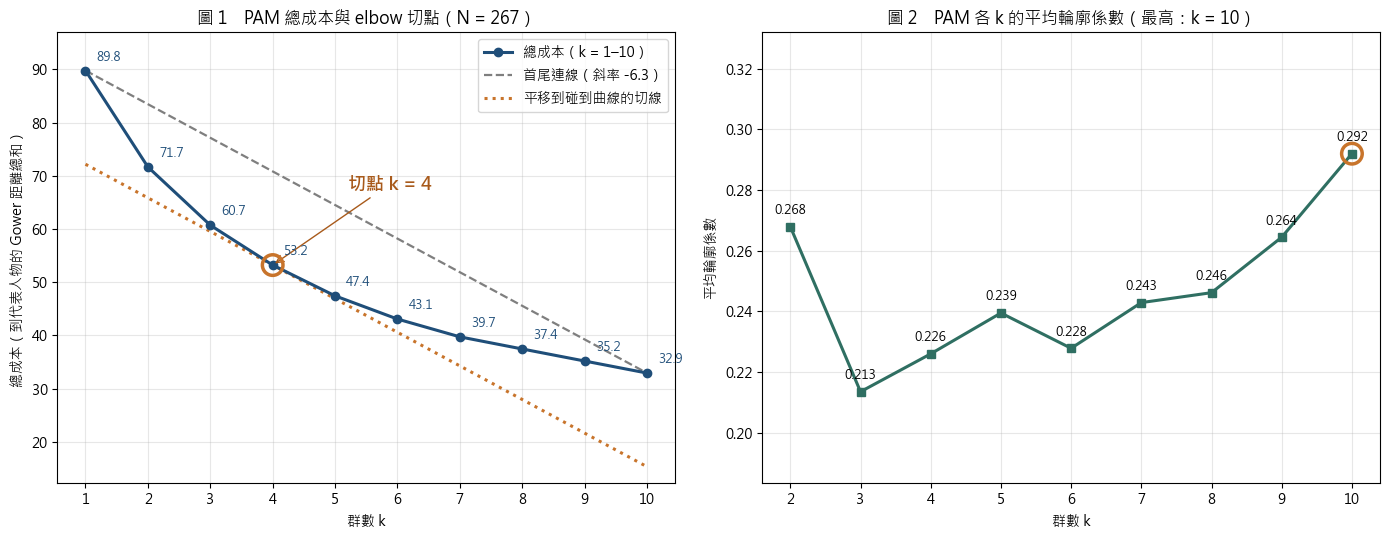

In [5]:
# Elbow 切點：平移首尾連線（同 k-means notebook 的做法）
w = res["總成本"]
ks = np.array(w.index, dtype=float)
slope = (w.iloc[-1] - w.iloc[0]) / (ks[-1] - ks[0])
chord = w.iloc[0] + slope * (ks - ks[0])
gap = pd.Series(chord - w.values, index=w.index)
k_elbow = int(gap.idxmax())
k_sil = int(res["輪廓係數"].idxmax())
tan_tbl = pd.DataFrame({"總成本": w, "首尾連線的值": chord, "連線 − 總成本": gap,
                        "比前一個 k 減少": res["比前一個 k 減少"], "輪廓係數": res["輪廓係數"]})
print(f"表 4　平移首尾連線找切點：連線斜率 {slope:.2f}（平均每多一群總成本減少 {-slope:.2f}）；"
      f"切點 k = {k_elbow}（距離 {gap.max():.2f}）；輪廓係數最高的 k = {k_sil}（{res['輪廓係數'].max():.3f}）")
display(tan_tbl.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ax = axes[0]
ax.plot(ks, w.values, marker="o", color="#1f4e79", linewidth=2.2, label="總成本（k = 1–10）", zorder=3)
ax.plot([ks[0], ks[-1]], [w.iloc[0], w.iloc[-1]], linestyle="--", color="#7f7f7f", linewidth=1.6,
        label=f"首尾連線（斜率 {slope:.1f}）")
ax.plot(ks, chord - gap.max(), linestyle=":", color="#C8742B", linewidth=2.2, label="平移到碰到曲線的切線")
ye = w.loc[k_elbow]
ax.scatter([k_elbow], [ye], s=220, facecolors="none", edgecolors="#C8742B", linewidths=2.5, zorder=4)
ax.annotate(f"切點 k = {k_elbow}", xy=(k_elbow, ye), xytext=(k_elbow + 1.2, ye + (w.max() - w.min()) * 0.25),
            fontsize=13, color="#A85A1B", fontweight="bold", arrowprops=dict(arrowstyle="->", color="#A85A1B"))
for k, v in w.items():
    ax.annotate(f"{v:.1f}", (k, v), textcoords="offset points", xytext=(8, 7), ha="left", fontsize=9, color="#1f4e79")
ax.set_title(f"圖 1　PAM 總成本與 elbow 切點（N = {len(D)}）")
ax.set_xlabel("群數 k")
ax.set_ylabel("總成本（到代表人物的 Gower 距離總和）")
ax.set_xticks(ks)
ax.set_ylim(min((chord - gap.max()).min(), w.min()) - 3, w.max() * 1.08)
ax.legend(loc="upper right", fontsize=10)
ax.grid(alpha=.3)

ax = axes[1]
r2 = res.dropna(subset=["輪廓係數"])
ax.plot(r2.index, r2["輪廓係數"], marker="s", color="#2f6f62", linewidth=2.2)
for k, v in r2["輪廓係數"].items():
    ax.annotate(f"{v:.3f}", (k, v), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.scatter([k_sil], [r2.loc[k_sil, "輪廓係數"]], s=220, facecolors="none", edgecolors="#C8742B", linewidths=2.5, zorder=4)
ax.set_title(f"圖 2　PAM 各 k 的平均輪廓係數（最高：k = {k_sil}）")
ax.set_xlabel("群數 k")
ax.set_ylabel("平均輪廓係數")
ax.set_xticks(r2.index)
ax.set_ylim(r2["輪廓係數"].min() - 0.03, r2["輪廓係數"].max() + 0.04)
ax.grid(alpha=.3)
fig.tight_layout()
asset_dir = PROJECT_ROOT / "finding" / "candidate_pam_gower_assets"
asset_dir.mkdir(exist_ok=True)
fig.savefig(asset_dir / "pam_choose_k.png", dpi=200)
plt.show()


In [6]:
# 敏感度檢查：排除年齡來自報導或約略值者（年齡全距沿用全樣本，距離尺度一致）
keep = df["G1_age_basis"].isin(["birth_date", "existing_source"]).to_numpy()
age_range = df["age"].max() - df["age"].min()
D_s = gower(df.loc[keep], age_range=age_range)
res_s = run_all(D_s)
cmp = pd.DataFrame({"全樣本 減少幅度（%）": res["減少幅度（%）"], "全樣本 輪廓係數": res["輪廓係數"],
                    "排除後 減少幅度（%）": res_s["減少幅度（%）"], "排除後 輪廓係數": res_s["輪廓係數"],
                    "排除後 最小群人數": res_s["最小群人數"]})
print(f"表 5　敏感度檢查：全樣本（N = {len(df)}）與排除報導／約略年齡者（N = {int(keep.sum())}）")
display(cmp.round(3))
w_s = res_s["總成本"]; ks_s = np.array(w_s.index, float)
chord_s = w_s.iloc[0] + (w_s.iloc[-1] - w_s.iloc[0]) / 9 * (ks_s - 1)
print("排除後：elbow 切點 k =", int(pd.Series(chord_s - w_s.values, index=w_s.index).idxmax()),
      "；輪廓係數最高的 k =", int(res_s["輪廓係數"].idxmax()))


表 5　敏感度檢查：全樣本（N = 267）與排除報導／約略年齡者（N = 245）


,全樣本 減少幅度（%）,全樣本 輪廓係數,排除後 減少幅度（%）,排除後 輪廓係數,排除後 最小群人數
k,,,,,
1,NaN,NaN,NaN,NaN,245
2,20.178,0.268,20.621,0.268,106
3,15.269,0.213,16.241,0.221,67
4,12.349,0.226,10.056,0.238,40
5,10.866,0.239,10.885,0.243,37
6,9.195,0.228,10.620,0.232,32
7,7.759,0.243,8.573,0.272,25
8,5.738,0.246,6.939,0.280,19
9,6.042,0.264,7.291,0.306,18


排除後：elbow 切點 k = 3 ；輪廓係數最高的 k = 10


### 最終分群（k = 4）與 k-means 比較

許以琳於 2026-11-10 選定 **k = 4**。以下用 PAM（Gower 距離）分成 4 群，群別依人數由多到少編為第 1–4 群，並列出每群的代表人物（medoid）、各群特徵與交叉表。

接著比較 PAM 與 k-means（同為 k = 4，k-means 依 [candidate_kmeans_elbow.ipynb](candidate_kmeans_elbow.ipynb) 的設定在此重算）哪一個比較穩健：

- **抽樣穩定度**：隨機抽出 80% 的候選人重新分群，重複 50 次，計算每次結果和全樣本結果的一致程度（ARI，1 = 完全相同）。兩個方法用同一批抽樣。
- **年齡誤差**：排除年齡來自報導或約略值的 22 人後重新分群，和全樣本結果比較。
- **兩方法的一致程度**：PAM 與 k-means 分出的群有多相似。

輪廓係數依賴各自的距離定義（Gower vs 歐氏距離），兩方法之間不能直接比大小，所以不用它比較。


In [7]:
K = 4
labP, costP, medP = pam(D, K)
order = pd.Series(labP).value_counts().index.tolist()
relabel = {old: new + 1 for new, old in enumerate(order)}
df["pam"] = pd.Series(labP).map(relabel).values
print(f"PAM k = {K}：總成本 {costP:.2f}，輪廓係數 {silhouette(D, labP):.3f}，各群人數",
      df["pam"].value_counts().sort_index().to_dict())

medoids = df.iloc[medP][["candidate_name", "office_type", "county_city", "age", "sex", "education", "party",
                         "first_time", "political_family"]].copy()
medoids.insert(0, "群別", [f"第 {relabel[i]} 群" for i in range(K)])
medoids = medoids.sort_values("群別").set_index("群別")
medoids.columns = ["代表人物", "公職", "縣市", "年齡", "性別", "學歷", "政黨", "首次參選", "政治家族"]
print("表 6　各群代表人物（medoid：群內與其他人 Gower 距離總和最小的候選人）")
display(medoids)

def ci95(x):
    m, sd, n = x.mean(), x.std(ddof=1), len(x)
    h = 1.96 * sd / np.sqrt(n)
    return m, m - h, m + h

def describe(g):
    m, lo, hi = ci95(g["age"])
    col = {"人數": len(g), "平均年齡": m, "年齡 95% CI 下限": lo, "年齡 95% CI 上限": hi,
           "女性（%）": 100 * (g["sex"] == "女").mean()}
    for lvl in ["研究所", "大學", "大學以下"]:
        col[f"學歷：{lvl}（%）"] = 100 * (g["education"] == lvl).mean()
    for pty in ["國民黨", "民進黨", "民眾黨", "其他政黨", "無黨籍／未經政黨推薦"]:
        col[f"政黨：{pty}（%）"] = 100 * (g["party"] == pty).mean()
    col["首次參選（%）"] = 100 * (g["first_time"] == "首次參選").mean()
    col["政治家族（%）"] = 100 * (g["political_family"] == "有").mean()
    return col

prof = {f"第 {c} 群": describe(g) for c, g in df.groupby("pam")}
prof["全樣本"] = describe(df)
profile = pd.DataFrame(prof)
print(f"表 7　PAM k = 4 各群特徵（N = {len(df)}；百分比分母為該群人數）")
display(profile.round(1))


PAM k = 4：總成本 53.21，輪廓係數 0.226，各群人數 {1: 76, 2: 74, 3: 66, 4: 51}
表 6　各群代表人物（medoid：群內與其他人 Gower 距離總和最小的候選人）


,代表人物,公職,縣市,年齡,性別,學歷,政黨,首次參選,政治家族
群別,,,,,,,,,
第 1 群,吳秀華,縣（市）長,臺東縣,53,女,研究所,國民黨,曾參選,無
第 2 群,林志誠,直轄市議員,高雄市,45,男,研究所,民進黨,曾參選,無
第 3 群,戴錫欽,直轄市議員,臺北市,60,男,研究所,國民黨,曾參選,無
第 4 群,李吳穎智,縣（市）長,臺東縣,47,男,大學,無黨籍／未經政黨推薦,首次參選,無


表 7　PAM k = 4 各群特徵（N = 267；百分比分母為該群人數）


,第 1 群,第 2 群,第 3 群,第 4 群,全樣本
人數,76.0,74.0,66.0,51.0,267.0
平均年齡,52.0,46.6,58.1,51.9,52.0
年齡 95% CI 下限,49.7,44.6,55.6,48.0,50.6
年齡 95% CI 上限,54.3,48.7,60.7,55.8,53.4
女性（%）,100.0,18.9,0.0,19.6,37.5
學歷：研究所（%）,72.4,78.4,66.7,23.5,63.3
學歷：大學（%）,19.7,18.9,16.7,58.8,26.2
學歷：大學以下（%）,7.9,2.7,16.7,17.6,10.5
政黨：國民黨（%）,50.0,0.0,69.7,2.0,31.8
政黨：民進黨（%）,25.0,77.0,0.0,7.8,30.0


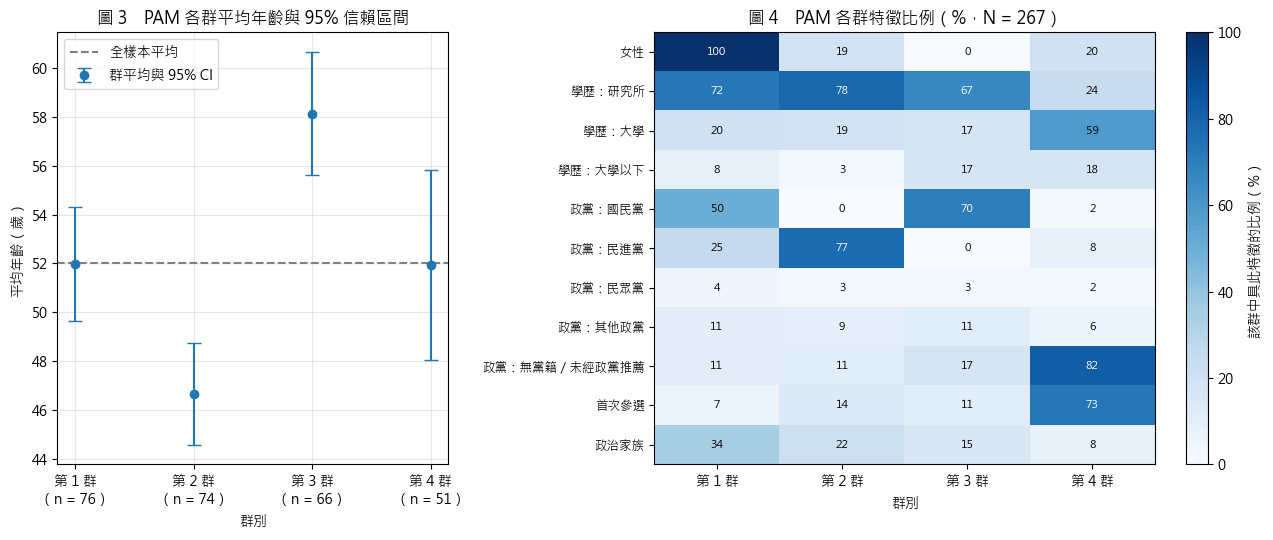

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
cl = [c for c in profile.columns if c != "全樣本"]
m = profile.loc["平均年齡", cl].astype(float)
lo = profile.loc["年齡 95% CI 下限", cl].astype(float)
hi = profile.loc["年齡 95% CI 上限", cl].astype(float)
ax.errorbar(range(len(cl)), m, yerr=[m - lo, hi - m], fmt="o", capsize=5, color="#1f77b4", label="群平均與 95% CI")
ax.axhline(profile.loc["平均年齡", "全樣本"], color="gray", linestyle="--", label="全樣本平均")
ax.set_xticks(range(len(cl)))
ax.set_xticklabels([f"{c}\n（n = {int(profile.loc['人數', c])}）" for c in cl])
ax.set_title("圖 3　PAM 各群平均年齡與 95% 信賴區間")
ax.set_xlabel("群別")
ax.set_ylabel("平均年齡（歲）")
ax.legend(loc="best")
ax.grid(alpha=.3)

ax = axes[1]
rows = [r for r in profile.index if r.endswith("（%）")]
H = profile.loc[rows, cl].astype(float)
im = ax.imshow(H.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(cl)))
ax.set_xticklabels(cl)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([r.replace("（%）", "") for r in rows], fontsize=9)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else "black")
ax.set_title(f"圖 4　PAM 各群特徵比例（%，N = {len(df)}）")
ax.set_xlabel("群別")
fig.colorbar(im, ax=ax, label="該群中具此特徵的比例（%）")
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "finding" / "candidate_pam_gower_assets" / "pam_k4_profile.png", dpi=200)
plt.show()


In [9]:
def xtab(var, title, col="pam"):
    rowlab = df[col].map(lambda c: f"第 {c} 群")
    t = pd.crosstab(rowlab, df[var], margins=True, margins_name="合計")
    pct = pd.crosstab(rowlab, df[var], normalize="index") * 100
    print(f"{title}（N = {len(df)}；第一個表為人數，第二個表為列百分比）")
    display(t)
    display(pct.round(1))

df["city_group"] = np.where(df["office_type"] == "直轄市議員", df["county_city"] + "議員", "首長")
xtab("office_type", "表 8　PAM 群別 × 公職類型")
xtab("party", "表 9　PAM 群別 × 政黨")
xtab("city_group", "表 10　PAM 群別 × 縣市（議員分臺北、高雄；首長合併一欄）")


表 8　PAM 群別 × 公職類型（N = 267；第一個表為人數，第二個表為列百分比）


office_type,直轄市議員,直轄市長,縣（市）長,合計
pam,,,,
第 1 群,57,5,14,76
第 2 群,58,4,12,74
第 3 群,45,10,11,66
第 4 群,27,4,20,51
合計,187,23,57,267


office_type,直轄市議員,直轄市長,縣（市）長
pam,,,
第 1 群,75.0,6.6,18.4
第 2 群,78.4,5.4,16.2
第 3 群,68.2,15.2,16.7
第 4 群,52.9,7.8,39.2


表 9　PAM 群別 × 政黨（N = 267；第一個表為人數，第二個表為列百分比）


party,其他政黨,國民黨,民眾黨,民進黨,無黨籍／未經政黨推薦,合計
pam,,,,,,
第 1 群,8,38,3,19,8,76
第 2 群,7,0,2,57,8,74
第 3 群,7,46,2,0,11,66
第 4 群,3,1,1,4,42,51
合計,25,85,8,80,69,267


party,其他政黨,國民黨,民眾黨,民進黨,無黨籍／未經政黨推薦
pam,,,,,
第 1 群,10.5,50.0,3.9,25.0,10.5
第 2 群,9.5,0.0,2.7,77.0,10.8
第 3 群,10.6,69.7,3.0,0.0,16.7
第 4 群,5.9,2.0,2.0,7.8,82.4


表 10　PAM 群別 × 縣市（議員分臺北、高雄；首長合併一欄）（N = 267；第一個表為人數，第二個表為列百分比）


city_group,臺北市議員,首長,高雄市議員,合計
pam,,,,
第 1 群,22,19,35,76
第 2 群,30,16,28,74
第 3 群,22,21,23,66
第 4 群,16,24,11,51
合計,90,80,97,267


city_group,臺北市議員,首長,高雄市議員
pam,,,
第 1 群,28.9,25.0,46.1
第 2 群,40.5,21.6,37.8
第 3 群,33.3,31.8,34.8
第 4 群,31.4,47.1,21.6


k-means k = 4 各群人數（應為 70／68／65／64）： {1: 70, 2: 68, 3: 65, 4: 64}


表 11　穩定度比較（k = 4；抽 80%＝214 人重跑 50 次，兩方法用同一批抽樣；排除報導／約略年齡者 N = 245）


,平均 ARI,最低 ARI,第 10 百分位,ARI ≥ 0.9 的比例（%）,排除 22 人後的 ARI
PAM,0.458,0.147,0.169,14.0,0.382
k-means,0.886,0.537,0.711,50.0,0.914


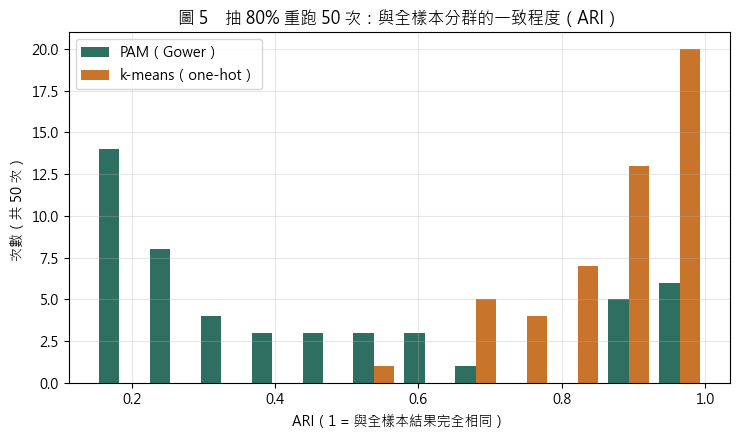

PAM 與 k-means（k = 4）分群的 ARI = 0.192
表 12　PAM 群別（列）× k-means 群別（欄）人數


kmeans,k-means 第 1 群,k-means 第 2 群,k-means 第 3 群,k-means 第 4 群,合計
pam,,,,,
PAM 第 1 群,15,30,12,19,76
PAM 第 2 群,14,0,15,45,74
PAM 第 3 群,11,38,17,0,66
PAM 第 4 群,30,0,21,0,51
合計,70,68,65,64,267


In [10]:
from math import comb

def ari(a, b):
    ct = pd.crosstab(pd.Series(a), pd.Series(b)).values
    sum_ij = sum(comb(int(n), 2) for n in ct.ravel())
    sum_a = sum(comb(int(n), 2) for n in ct.sum(1))
    sum_b = sum(comb(int(n), 2) for n in ct.sum(0))
    tot = comb(int(ct.sum()), 2)
    exp = sum_a * sum_b / tot
    mx = (sum_a + sum_b) / 2
    return (sum_ij - exp) / (mx - exp)

# 依 candidate_kmeans_elbow.ipynb 的設定重算 k-means（one-hot＋年齡 0–1、k-means++、50 組起點）
def kmeans(X, k, n_init=50, max_iter=300, tol=1e-8, seed=0):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        Cc = [X[rng.integers(len(X))]]
        for _ in range(1, k):
            d2 = np.min(((X[:, None, :] - np.array(Cc)[None]) ** 2).sum(-1), axis=1)
            Cc.append(X[rng.choice(len(X), p=d2 / d2.sum())] if d2.sum() > 0 else X[rng.integers(len(X))])
        Cc = np.array(Cc, dtype=float)
        for _ in range(max_iter):
            lab = ((X[:, None, :] - Cc[None]) ** 2).sum(-1).argmin(1)
            newC = np.array([X[lab == j].mean(0) if (lab == j).any() else Cc[j] for j in range(k)])
            shift = ((newC - Cc) ** 2).sum()
            Cc = newC
            if shift <= tol:
                break
        lab = ((X[:, None, :] - Cc[None]) ** 2).sum(-1).argmin(1)
        inertia = ((X - Cc[lab]) ** 2).sum()
        if best is None or inertia < best[1] - 1e-12:
            best = (lab, inertia)
    return best

def onehot(frame, age_min, age_max):
    X = pd.DataFrame(index=frame.index)
    X["age"] = (frame["age"] - age_min) / (age_max - age_min)
    X["female"] = (frame["sex"] == "女").astype(int)
    for lvl in ["大學以下", "大學", "研究所"]:
        X[lvl] = (frame["education"] == lvl).astype(int)
    for p in ["國民黨", "民進黨", "民眾黨", "其他政黨", "無黨籍／未經政黨推薦"]:
        X[p] = (frame["party"] == p).astype(int)
    X["first"] = (frame["first_time"] == "首次參選").astype(int)
    X["family"] = (frame["political_family"] == "有").astype(int)
    return X.values.astype(float)

amin, amax = df["age"].min(), df["age"].max()
Xk = onehot(df, amin, amax)
labK, _ = kmeans(Xk, K, n_init=50, seed=20261110 + K)
orderK = pd.Series(labK).value_counts().index.tolist()
df["kmeans"] = pd.Series(labK).map({o: i + 1 for i, o in enumerate(orderK)}).values
print("k-means k = 4 各群人數（應為 70／68／65／64）：", df["kmeans"].value_counts().sort_index().to_dict())

# (1) 抽 80% 重跑 50 次
rng = np.random.default_rng(20261110)
n = len(df); m = int(round(0.8 * n))
rows = []
for r in range(50):
    idx = np.sort(rng.choice(n, m, replace=False))
    lp, _, _ = pam(D[np.ix_(idx, idx)], K)
    lk, _ = kmeans(Xk[idx], K, n_init=10, seed=20261110 + 100 + r)
    rows.append({"PAM": ari(df["pam"].values[idx], lp), "k-means": ari(df["kmeans"].values[idx], lk)})
boot = pd.DataFrame(rows)
bsum = pd.DataFrame({"平均 ARI": boot.mean(), "最低 ARI": boot.min(),
                     "第 10 百分位": boot.quantile(.1), "ARI ≥ 0.9 的比例（%）": 100 * (boot >= 0.9).mean()})

# (2) 排除報導／約略年齡者
keep_idx = np.where(keep)[0]
lp_s, _, _ = pam(D[np.ix_(keep_idx, keep_idx)], K)
lk_s, _ = kmeans(Xk[keep_idx], K, n_init=50, seed=20261110 + K)
bsum["排除 22 人後的 ARI"] = [ari(df["pam"].values[keep_idx], lp_s), ari(df["kmeans"].values[keep_idx], lk_s)]
print(f"表 11　穩定度比較（k = 4；抽 80%＝{m} 人重跑 50 次，兩方法用同一批抽樣；排除報導／約略年齡者 N = {len(keep_idx)}）")
display(bsum.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.hist([boot["PAM"], boot["k-means"]], bins=np.linspace(min(boot.min().min(), 0.4), 1, 13),
        label=["PAM（Gower）", "k-means（one-hot）"], color=["#2f6f62", "#C8742B"])
ax.set_title("圖 5　抽 80% 重跑 50 次：與全樣本分群的一致程度（ARI）")
ax.set_xlabel("ARI（1 = 與全樣本結果完全相同）")
ax.set_ylabel("次數（共 50 次）")
ax.legend()
ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "finding" / "candidate_pam_gower_assets" / "stability_compare.png", dpi=200)
plt.show()

# (3) 兩方法的一致程度
print(f"PAM 與 k-means（k = 4）分群的 ARI = {ari(df['pam'], df['kmeans']):.3f}")
print("表 12　PAM 群別（列）× k-means 群別（欄）人數")
display(pd.crosstab(df["pam"].map(lambda c: f"PAM 第 {c} 群"), df["kmeans"].map(lambda c: f"k-means 第 {c} 群"),
                    margins=True, margins_name="合計"))


In [11]:
out_path = PROJECT_ROOT / "finding" / "candidate_pam_gower_assets" / "cluster_labels_pam_k4.csv"
lab_out = df[["candidate_key", "candidate_name", "office_type", "county_city", "pam"]].rename(columns={"pam": "cluster"})
lab_out.to_csv(out_path, index=False, encoding="utf-8-sig")
chk = pd.read_csv(out_path, dtype=str, encoding="utf-8-sig")
assert len(chk) == len(df) and chk["candidate_key"].is_unique
assert (chk["cluster"].astype(int).values == df["pam"].values).all()
print("已存：", out_path.relative_to(PROJECT_ROOT).as_posix(), "；", len(chk), "列；SHA-256 =",
      hashlib.sha256(out_path.read_bytes()).hexdigest())


已存： finding/candidate_pam_gower_assets/cluster_labels_pam_k4.csv ； 267 列；SHA-256 = 2c6de62e76072cfff765dd1a0c1a88d5d5d6b1132cc861a33800a49bcf353fac


### 結果說明：該如何選 k

**樣本與距離。** 267 位候選人，G1–G6 無缺值。Gower 距離兩兩平均 0.438、中位數 0.404；有 29 對候選人六個變數完全相同（距離 0）。

**依據一：elbow（表 3–4、圖 1）。** 總成本從 k = 1 的 89.8 降到 k = 10 的 32.9。每多一群的減少量：k = 2 為 18.1、k = 3 為 10.9、k = 4 為 7.5、k = 5 為 5.8，之後都在 4.4 以下。首尾連線斜率 −6.32（平均每多一群減少 6.32）；k = 2–4 每多一群的減少量都高於平均，k = 5 起低於平均，平移切點為 **k = 4**。不過 k = 3、4、5 離連線的距離很接近（16.42、17.60、17.07），曲線在這一段彎得很緩，手肘並不尖銳。

**依據二：輪廓係數（表 3、圖 2）。** 介於 0.213–0.292，全部偏低。依 Kaufman & Rousseeuw 的經驗標準，0.25 以下代表「沒有找到明顯的群結構」，0.26–0.50 是「結構弱」。k = 2 有局部高點 0.268；k = 3 最低；之後隨 k 增加而上升，k = 10 最高 0.292。這種「群越多分數越高」的走勢，在變數多為類別、很多人特徵相同的資料中常見（群切得越細，越多人和完全相同的人分在一起），不代表 10 群才是真正的結構，所以不直接取最大值。

**依據三：群大小與可解釋性。** k = 2 太粗（158／109），難以描述候選人類型；k = 4 時最小群 51 人，k = 5 為 43 人；k ≥ 7 最小群降到 27 人以下，後續比較各群策略時每群人數太少。

**敏感度（表 5）。** 排除年齡來自報導或約略值的 22 人後，輪廓係數的走勢相同，但 elbow 切點從 4 變成 3，再次顯示 3–5 之間差異不大。

**建議怎麼選。** 綜合三個依據，合理範圍是 k = 4 或 5；許以琳選定 **k = 4**（elbow 切點、可與 k-means 直接比較）。兩者的輪廓係數都偏低，結果應當作描述性的分類。

**PAM k = 4 的四群（表 6–7、圖 3–4）。**

| 群別 | 人數 | 代表人物（medoid） | 主要特徵 |
| --- | --- | --- | --- |
| 第 1 群 | 76 | 吳秀華（臺東縣長候選人，53 歲女性、研究所、國民黨） | 全為女性；國民黨 50%、民進黨 25%；研究所 72%；政治家族 34%（四群最高）；首次參選 7% |
| 第 2 群 | 74 | 林志誠（高雄市議員候選人，45 歲男性、研究所、民進黨） | 民進黨 77%；男性 81%；平均 46.6 歲（最年輕）；研究所 78% |
| 第 3 群 | 66 | 戴錫欽（臺北市議員候選人，60 歲男性、研究所、國民黨） | 全為男性；國民黨 70%；平均 58.1 歲（最年長） |
| 第 4 群 | 51 | 李吳穎智（臺東縣長候選人，47 歲男性、大學、無黨籍、首次參選） | 無黨籍 82%；首次參選 73%；大學 59%；縣市長占 39% |

年齡上，第 2 群（46.6 歲）與第 3 群（58.1 歲）的 95% 信賴區間不重疊。和 k-means 相比，PAM 不再只沿政黨與學歷切開，性別與首次參選也成為主要的分群軸，比較接近「候選人類型」。交叉表（表 8–10）顯示第 4 群的縣（市）長比例最高（39%），其他三群以議員為主。

**穩健性比較（表 11–12、圖 5）。**

| | PAM（Gower） | k-means（one-hot） |
| --- | --- | --- |
| 抽 80% 重跑 50 次，平均 ARI | 0.458 | 0.886 |
| 同上，ARI ≥ 0.9 的比例 | 14% | 50% |
| 排除報導／約略年齡 22 人後的 ARI | 0.382 | 0.914 |

PAM 的結果對樣本變動非常敏感：抽樣後有一半以上的次數 ARI 低於 0.3，也就是群別大幅重組；k-means 則大多維持原狀。兩個方法彼此的 ARI 只有 0.192（表 12），分出的群很不一樣。

**為什麼 PAM 不穩？** Gower 距離中五個變數是「相同／不同」，兩兩距離只有少數幾種值，很多候選人和好幾群的代表人物距離相同或幾乎相同；再加上 elbow 平緩、輪廓係數偏低，表示資料本身沒有明顯的群，換掉幾個人就可能換掉代表人物，整體分群隨之改變。k-means 穩定，是因為 one-hot 讓政黨與學歷佔了大部分的距離，而政黨與學歷本身就是清楚的類別，所以每次都切在同樣的地方，這種穩定主要來自政黨，不代表找到了候選人類型。

**建議。** 若後續要用群別比較各群的競選策略，需要每位候選人的群別可靠：k-means 較穩健，但它的群幾乎等於「政黨＋學歷」，比較時需說明差異可能就是政黨差異；PAM 的四群在描述上較有意義（女性、民進黨年輕男性、國民黨年長男性、無黨籍素人），但群別不穩定，只適合描述整體樣貌，不宜當作後續比較的分組。

**限制。** Gower 距離中六個變數權重相同，學歷依 proposal 當類別處理（不考慮高低順序）；PAM 以 numpy 實作（BUILD＋SWAP），因為本機的應用程式控制原則封鎖了 scikit-learn。輪廓係數與總成本都依賴距離的定義，換成其他權重可能得到不同的 k。

<!-- Completion: run all cells in order from a clean kernel and save the actual
outputs in this ipynb. Inspect the notebook's code, tables, and figures for
readable labels, nonoverlapping text, and agreement with the takeaways. Deliver
the executed ipynb directly and record its actual execution status. Produce HTML
only when separately requested, never as a default export or a condition of completion. -->
